Name: **Sufyan Afzal**

Reg No: **FA23-BAI-061**

# Lab 4 Self Organizing Maps (SOM) for ANN

Task 1

Part A
Random colors generated successfully
First 5 colors:
[[0.37454012 0.95071431 0.73199394]
 [0.59865848 0.15601864 0.15599452]
 [0.05808361 0.86617615 0.60111501]
 [0.70807258 0.02058449 0.96990985]
 [0.83244264 0.21233911 0.18182497]]

Part B
Weight grid created successfully
Weight grid shape: (10, 10, 3)
First neuron weights: [0.16893506 0.27859034 0.17701048]

Part C


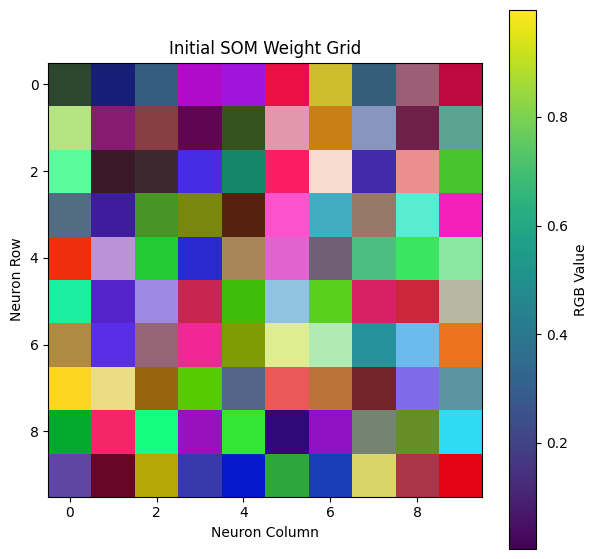


Part D
Data shape: (200, 3)
Data minimum value: 0.005061583846218687
Data maximum value: 0.9997176732861306
Weight grid shape: (10, 10, 3)
Weight grid minimum value: 0.004632023004602859
Weight grid maximum value: 0.9968742518459474


In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("Part A")
np.random.seed(42)
data = np.random.rand(200,3)
print("Random colors generated successfully")
print("First 5 colors:")
print(data[:5])

print("\nPart B")
grid_size = 10
weights = np.random.rand(grid_size,grid_size,3)
print("Weight grid created successfully")
print("Weight grid shape:",weights.shape)
print("First neuron weights:",weights[0,0])

print("\nPart C")
plt.figure(figsize=(7,7))
plt.imshow(weights)
plt.title("Initial SOM Weight Grid")
plt.xlabel("Neuron Column")
plt.ylabel("Neuron Row")
plt.colorbar(label="RGB Value")
plt.show()

print("\nPart D")
print("Data shape:",data.shape)
print("Data minimum value:",np.min(data))
print("Data maximum value:",np.max(data))
print("Weight grid shape:",weights.shape)
print("Weight grid minimum value:",np.min(weights))
print("Weight grid maximum value:",np.max(weights))

Task 2

Part A
First sample: [0.37454012 0.95071431 0.73199394]
First neuron weights: [0.16893506 0.27859034 0.17701048]
Euclidean distance: 0.8955616699152169

Part B
Selected sample: [0.77714692 0.55840425 0.42422201]
Distance array shape: (10, 10)
Distance array:
[[0.71367431 0.81665979 0.60810177 0.64633495 0.67185308 0.53823862
  0.30715763 0.60112295 0.25024242 0.55007602]
 [0.35377187 0.51399388 0.42851756 0.67832577 0.68266322 0.28117128
  0.34280094 0.40200584 0.56982094 0.44786916]
 [0.62731468 0.75740016 0.70485838 0.78336505 0.69787379 0.49199315
  0.53444521 0.69247766 0.21189714 0.58990491]
 [0.47986143 0.71933312 0.55856393 0.4764106  0.7099687  0.49973703
  0.63329769 0.20158775 0.69736299 0.56371912]
 [0.54425101 0.41946575 0.71547104 0.82709826 0.13437864 0.43762223
  0.38556294 0.51799301 0.64418714 0.46446078]
 [0.78919096 0.71274367 0.49586783 0.42215652 0.6830397  0.53794935
  0.59725396 0.43728361 0.45307945 0.27603462]
 [0.19208726 0.75007356 0.25256991 0.46825287 0.491

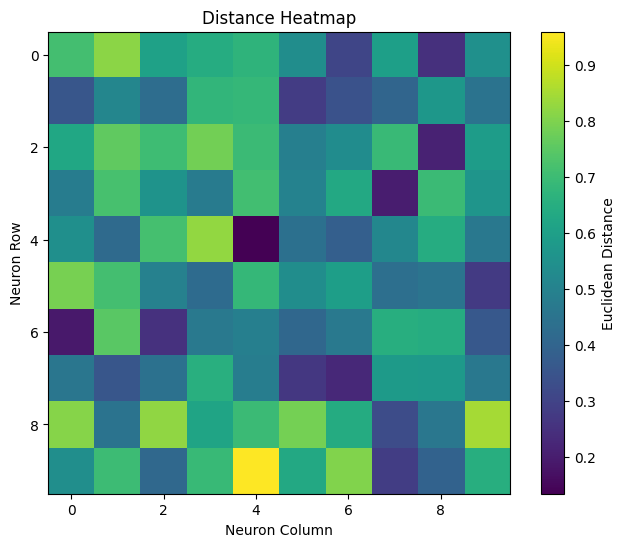


Part D
Smallest distance: 0.13437863807304615
BMU row: 4
BMU column: 4
BMU position: (4, 4)


In [2]:
print("Part A")
def euclidean_distance(a,b):
    distance = np.sqrt(np.sum((a - b) ** 2))
    return distance

a = data[0]
b = weights[0,0]
print("First sample:",a)
print("First neuron weights:",b)
print("Euclidean distance:",euclidean_distance(a,b))

print("\nPart B")
sample = data[np.random.randint(0,len(data))]
distances = np.sqrt(np.sum((weights - sample) ** 2,axis=2))
print("Selected sample:",sample)
print("Distance array shape:",distances.shape)
print("Distance array:")
print(distances)

print("\nPart C")
plt.figure(figsize=(8,6))
plt.imshow(distances,cmap="viridis")
plt.title("Distance Heatmap")
plt.xlabel("Neuron Column")
plt.ylabel("Neuron Row")
plt.colorbar(label="Euclidean Distance")
plt.show()

print("\nPart D")
min_distance = np.min(distances)
bmu_position = np.unravel_index(np.argmin(distances),distances.shape)
print("Smallest distance:",min_distance)
print("BMU row:",bmu_position[0])
print("BMU column:",bmu_position[1])
print("BMU position:",bmu_position)

Task 3

Part A
Sample: [0.37454012 0.95071431 0.73199394]
BMU position: (3, 8)
BMU distance: 0.10409052615689075

Part B
BMU Results for 5 Samples
--------------------------------------------------
Sample Number: 1 | BMU Position: (3, 8) | Distance: 0.10409052615689075
Sample Number: 2 | BMU Position: (7, 7) | Distance: 0.14841062637567634
Sample Number: 3 | BMU Position: (5, 0) | Distance: 0.09793635649206811
Sample Number: 4 | BMU Position: (0, 4) | Distance: 0.13946185619490198
Sample Number: 5 | BMU Position: (5, 8) | Distance: 0.08591311638127803

Part C


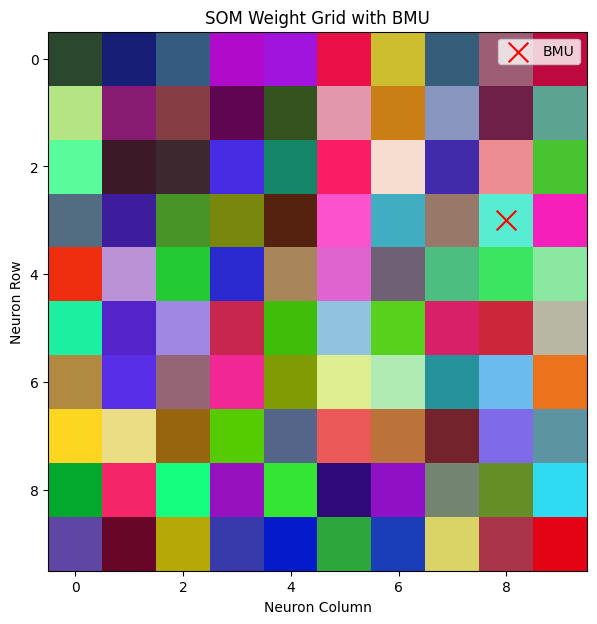


Part D
Hit Map:
[[1 1 2 1 4 1 4 2 2 2]
 [2 2 2 0 2 4 1 1 1 3]
 [0 5 1 1 3 0 6 1 4 0]
 [0 5 3 0 2 0 3 0 3 1]
 [2 3 3 4 4 2 0 1 3 4]
 [3 1 2 0 0 2 6 0 1 1]
 [1 4 0 2 1 2 4 4 2 3]
 [3 2 3 3 0 3 4 3 5 1]
 [5 1 1 2 0 1 0 2 1 3]
 [4 1 2 1 0 2 0 4 1 1]]
Total samples assigned: 200


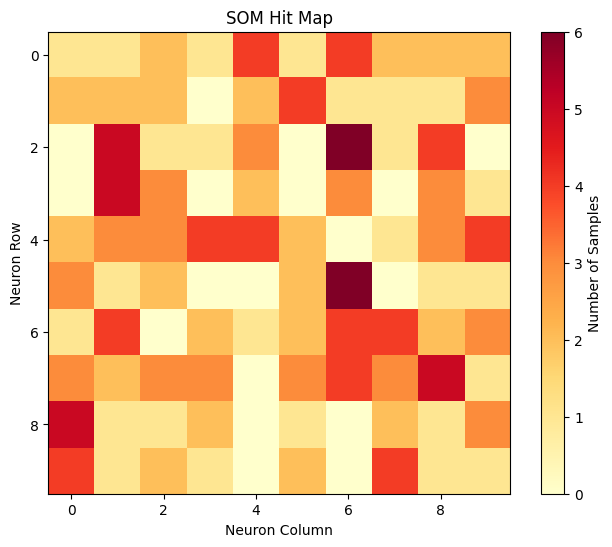

In [3]:
print("Part A")
def find_bmu(weights,x):
    distances = np.sqrt(np.sum((weights - x) ** 2,axis=2))
    bmu_position = np.unravel_index(np.argmin(distances),distances.shape)
    return bmu_position

sample = data[0]
bmu = find_bmu(weights,sample)
print("Sample:",sample)
print("BMU position:",bmu)
print("BMU distance:",euclidean_distance(sample,weights[bmu[0],bmu[1]]))

print("\nPart B")
print("BMU Results for 5 Samples")
print("-" * 50)
for i in range(5):
    sample = data[i]
    bmu = find_bmu(weights,sample)
    distance = euclidean_distance(sample,weights[bmu[0],bmu[1]])
    print("Sample Number:",i + 1,"| BMU Position:",bmu,"| Distance:",distance)

print("\nPart C")
sample = data[0]
bmu = find_bmu(weights,sample)
plt.figure(figsize=(7,7))
plt.imshow(weights)
plt.scatter(bmu[1],bmu[0],color="red",marker="x",s=200,label="BMU")
plt.title("SOM Weight Grid with BMU")
plt.xlabel("Neuron Column")
plt.ylabel("Neuron Row")
plt.legend()
plt.show()

print("\nPart D")
hit_map = np.zeros((grid_size,grid_size),dtype=int)
for i in range(len(data)):
    bmu = find_bmu(weights,data[i])
    hit_map[bmu[0],bmu[1]] += 1
print("Hit Map:")
print(hit_map)
print("Total samples assigned:",np.sum(hit_map))
plt.figure(figsize=(8,6))
plt.imshow(hit_map,cmap="YlOrRd")
plt.title("SOM Hit Map")
plt.xlabel("Neuron Column")
plt.ylabel("Neuron Row")
plt.colorbar(label="Number of Samples")
plt.show()

Task 4

Part A
BMU position: (5, 5)
Radius: 1
Neighborhood shape: (10, 10)
Neighborhood value at BMU: 1.0

Part B


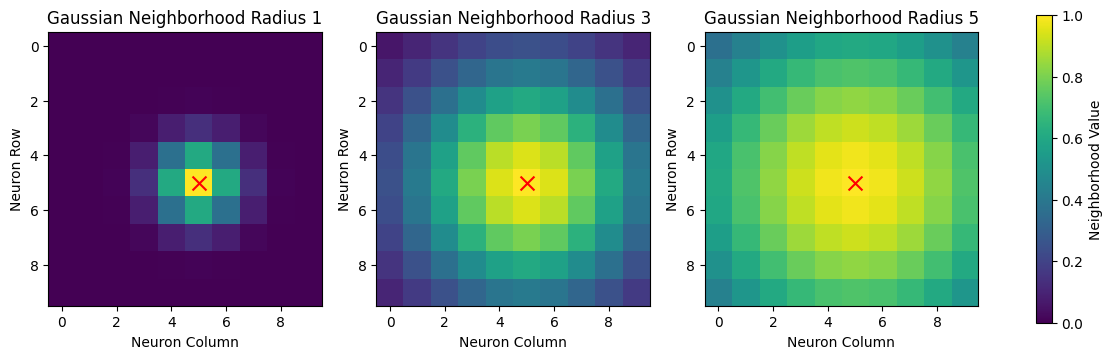


Part C


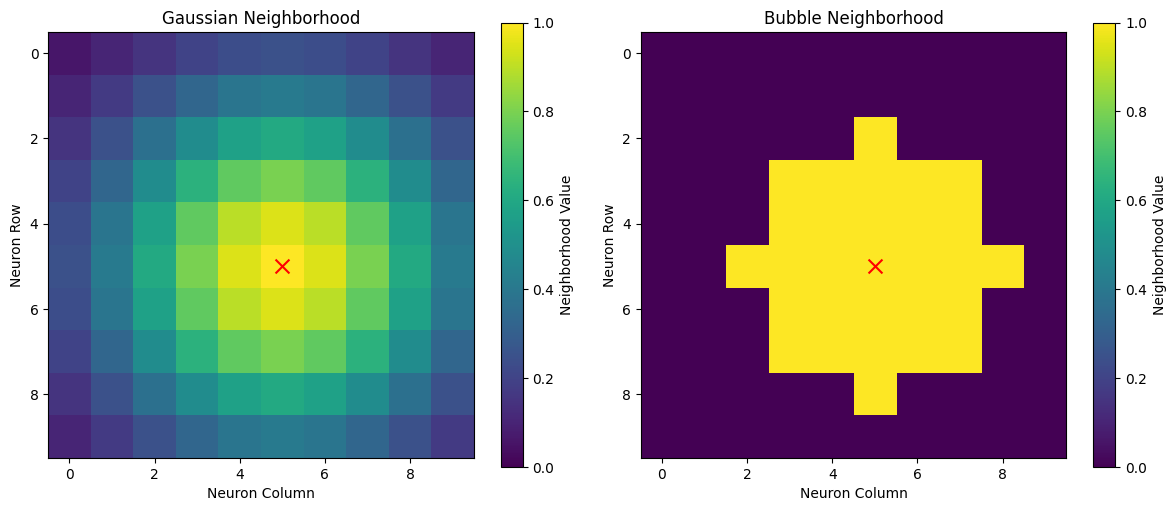


Part D
BMU position: (5, 5)
Radius: 2
Neighborhood value at BMU: 1.0
Neighborhood value at neuron (5, 8) : 0.32465246735834974


In [4]:
print("Part A")
def neighborhood(grid_size,bmu,radius):
    rows,cols = np.indices((grid_size,grid_size))
    distances = np.sqrt((rows - bmu[0]) ** 2 + (cols - bmu[1]) ** 2)
    h = np.exp(-(distances ** 2) / (2 * radius ** 2))
    return h

bmu = (5,5)
radius = 1
h = neighborhood(grid_size,bmu,radius)
print("BMU position:",bmu)
print("Radius:",radius)
print("Neighborhood shape:",h.shape)
print("Neighborhood value at BMU:",h[bmu[0],bmu[1]])

print("\nPart B")
radii = [1,3,5]
fig,axes = plt.subplots(1,3,figsize=(15,5))
for i,radius in enumerate(radii):
    h = neighborhood(grid_size,bmu,radius)
    image = axes[i].imshow(h,cmap="viridis",vmin=0,vmax=1)
    axes[i].set_title("Gaussian Neighborhood Radius " + str(radius))
    axes[i].set_xlabel("Neuron Column")
    axes[i].set_ylabel("Neuron Row")
    axes[i].scatter(bmu[1],bmu[0],color="red",marker="x",s=100)
fig.colorbar(image,ax=axes.ravel().tolist(),label="Neighborhood Value",shrink=0.8)
plt.show()

print("\nPart C")
def bubble_neighborhood(grid_size,bmu,radius):
    rows,cols = np.indices((grid_size,grid_size))
    distances = np.sqrt((rows - bmu[0]) ** 2 + (cols - bmu[1]) ** 2)
    h = np.where(distances <= radius,1.0,0.0)
    return h

gaussian_h = neighborhood(grid_size,bmu,3)
bubble_h = bubble_neighborhood(grid_size,bmu,3)
fig,axes = plt.subplots(1,2,figsize=(12,5))
image1 = axes[0].imshow(gaussian_h,cmap="viridis",vmin=0,vmax=1)
axes[0].set_title("Gaussian Neighborhood")
axes[0].set_xlabel("Neuron Column")
axes[0].set_ylabel("Neuron Row")
axes[0].scatter(bmu[1],bmu[0],color="red",marker="x",s=100)
image2 = axes[1].imshow(bubble_h,cmap="viridis",vmin=0,vmax=1)
axes[1].set_title("Bubble Neighborhood")
axes[1].set_xlabel("Neuron Column")
axes[1].set_ylabel("Neuron Row")
axes[1].scatter(bmu[1],bmu[0],color="red",marker="x",s=100)
fig.colorbar(image1,ax=axes[0],label="Neighborhood Value")
fig.colorbar(image2,ax=axes[1],label="Neighborhood Value")
plt.tight_layout()
plt.show()

print("\nPart D")
radius = 2
h = neighborhood(grid_size,bmu,radius)
neuron_3_steps = (5,8)
print("BMU position:",bmu)
print("Radius:",radius)
print("Neighborhood value at BMU:",h[bmu[0],bmu[1]])
print("Neighborhood value at neuron",neuron_3_steps,":",h[neuron_3_steps[0],neuron_3_steps[1]])

Task 5

Part A
Weight update function created successfully

Part B
Selected sample: [0.37454012 0.95071431 0.73199394]
BMU position: (3, 8)
Learning rate: 0.5
Radius: 2


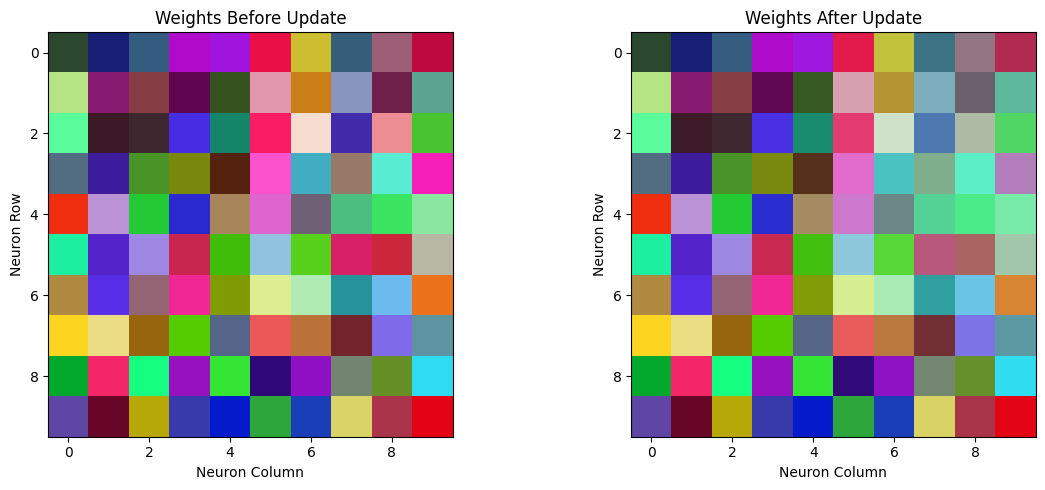


Part C
Total absolute change in weights: 8.68310343621436

Part D
Distance before update: 0.10409052615689075
Distance after update: 0.05204526307844544
Distance decreased after the update

Part E
Updated weights saved successfully
Updated weight grid shape: (10, 10, 3)


In [5]:
print("Part A")
def update_weights(weights,x,bmu,learning_rate,radius):
    new_weights = weights.copy()
    h = neighborhood(weights.shape[0],bmu,radius)
    for i in range(weights.shape[0]):
        for j in range(weights.shape[1]):
            new_weights[i,j] += learning_rate * h[i,j] * (x - new_weights[i,j])
    return new_weights

print("Weight update function created successfully")

print("\nPart B")
sample = data[0]
bmu = find_bmu(weights,sample)
learning_rate = 0.5
radius = 2
weights_before = weights.copy()
weights_after = update_weights(weights_before,sample,bmu,learning_rate,radius)
print("Selected sample:",sample)
print("BMU position:",bmu)
print("Learning rate:",learning_rate)
print("Radius:",radius)
fig,axes = plt.subplots(1,2,figsize=(12,5))
axes[0].imshow(weights_before)
axes[0].set_title("Weights Before Update")
axes[0].set_xlabel("Neuron Column")
axes[0].set_ylabel("Neuron Row")
axes[1].imshow(weights_after)
axes[1].set_title("Weights After Update")
axes[1].set_xlabel("Neuron Column")
axes[1].set_ylabel("Neuron Row")
plt.tight_layout()
plt.show()

print("\nPart C")
total_change = np.sum(np.abs(weights_after - weights_before))
print("Total absolute change in weights:",total_change)

print("\nPart D")
distance_before = euclidean_distance(sample,weights_before[bmu[0],bmu[1]])
distance_after = euclidean_distance(sample,weights_after[bmu[0],bmu[1]])
print("Distance before update:",distance_before)
print("Distance after update:",distance_after)
if distance_after < distance_before:
    print("Distance decreased after the update")
else:
    print("Distance did not decrease after the update")

print("\nPart E")
weights = weights_after.copy()
print("Updated weights saved successfully")
print("Updated weight grid shape:",weights.shape)

Task 6

Part A
Training function created successfully

Part B
Training completed successfully
Number of iterations: 1000
Trained weights shape: (10, 10, 3)
Number of learning rate values: 10
Number of radius values: 10

Part C


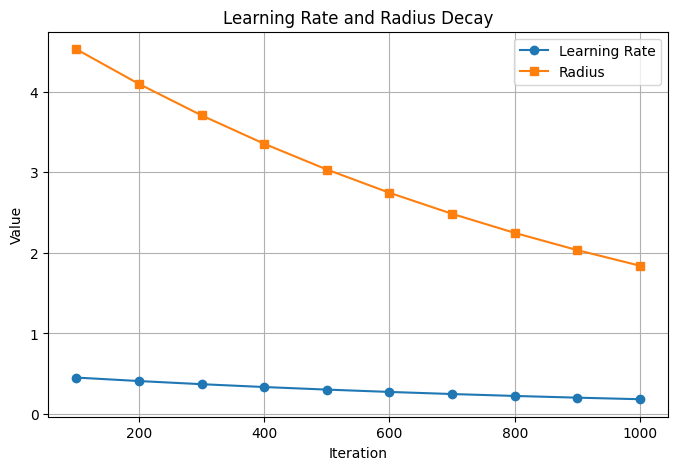


Part D


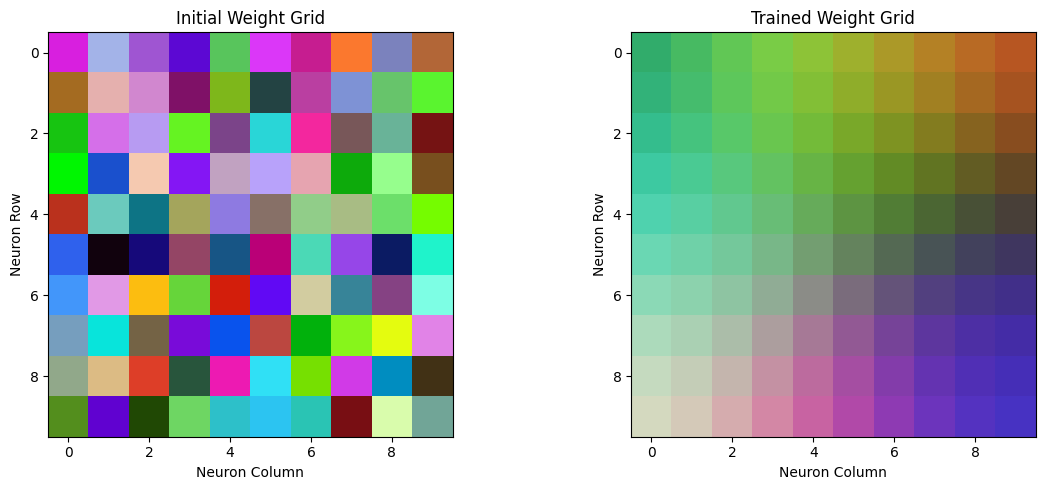

Figure saved as task6_result.png


In [6]:
print("Part A")
initial_weights = np.random.rand(grid_size,grid_size,3)
def train_som(data,grid_size,iterations,lr_start,radius_start):
    trained_weights = initial_weights.copy()
    learning_rate_history = []
    radius_history = []
    for iteration in range(iterations):
        learning_rate = lr_start * np.exp(-iteration / iterations)
        radius = radius_start * np.exp(-iteration / iterations)
        sample = data[np.random.randint(0,len(data))]
        distances = np.sqrt(np.sum((trained_weights - sample) ** 2,axis=2))
        bmu = np.unravel_index(np.argmin(distances),distances.shape)
        h = neighborhood(grid_size,bmu,max(radius,0.01))
        trained_weights += learning_rate * h[:,:,np.newaxis] * (sample - trained_weights)
        if (iteration + 1) % 100 == 0:
            learning_rate_history.append(learning_rate)
            radius_history.append(radius)
    return trained_weights,learning_rate_history,radius_history

print("Training function created successfully")

print("\nPart B")
iterations = 1000
lr_start = 0.5
radius_start = 5
trained_weights,learning_rate_history,radius_history = train_som(data,grid_size,iterations,lr_start,radius_start)
print("Training completed successfully")
print("Number of iterations:",iterations)
print("Trained weights shape:",trained_weights.shape)
print("Number of learning rate values:",len(learning_rate_history))
print("Number of radius values:",len(radius_history))

print("\nPart C")
plt.figure(figsize=(8,5))
plt.plot(range(100,iterations + 1,100),learning_rate_history,marker="o",label="Learning Rate")
plt.plot(range(100,iterations + 1,100),radius_history,marker="s",label="Radius")
plt.title("Learning Rate and Radius Decay")
plt.xlabel("Iteration")
plt.ylabel("Value")
plt.legend()
plt.grid()
plt.show()

print("\nPart D")
fig,axes = plt.subplots(1,2,figsize=(12,5))
axes[0].imshow(initial_weights)
axes[0].set_title("Initial Weight Grid")
axes[0].set_xlabel("Neuron Column")
axes[0].set_ylabel("Neuron Row")
axes[1].imshow(trained_weights)
axes[1].set_title("Trained Weight Grid")
axes[1].set_xlabel("Neuron Column")
axes[1].set_ylabel("Neuron Row")
plt.tight_layout()
plt.savefig("task6_result.png",dpi=300,bbox_inches="tight")
plt.show()
print("Figure saved as task6_result.png")

Task 7

Part A
Initial quantization error: 0.13467422934120188

Part B
Training function updated successfully

Part C
Iteration: 250 Quantization Error: 0.34412872194263455
Iteration: 500 Quantization Error: 0.3217525329111013
Iteration: 750 Quantization Error: 0.31783411860885563
Iteration: 1000 Quantization Error: 0.33027795471529436
Iteration: 1250 Quantization Error: 0.3434483111020316
Iteration: 1500 Quantization Error: 0.32606338976159605
Iteration: 1750 Quantization Error: 0.3266695370989876
Iteration: 2000 Quantization Error: 0.2875066960379634
Iteration: 2250 Quantization Error: 0.29401908700600177
Iteration: 2500 Quantization Error: 0.28243761832306746
Iteration: 2750 Quantization Error: 0.26134643675722585
Iteration: 3000 Quantization Error: 0.2700640576069422
Iteration: 3250 Quantization Error: 0.24657446707367445
Iteration: 3500 Quantization Error: 0.24069017300587753
Iteration: 3750 Quantization Error: 0.23876762574967703
Iteration: 4000 Quantization Error: 0.24922539310633687
It

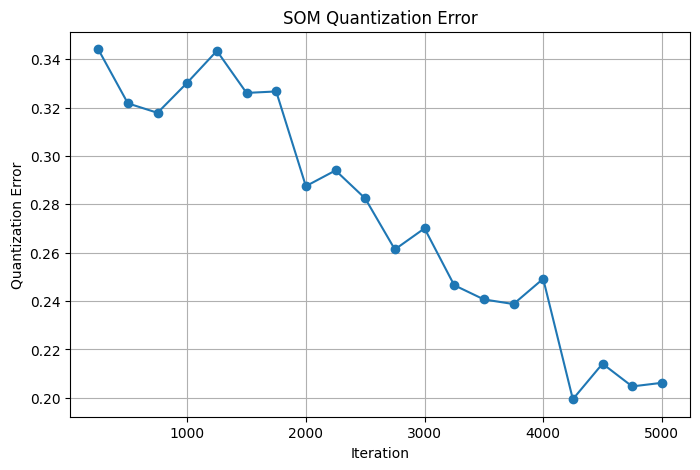


Part D
First quantization error: 0.34412872194263455
Last quantization error: 0.20620602146677552
Percentage reduction: 40.07881111965145 %


In [7]:
print("Part A")
def quantization_error(data,weights):
    total_distance = 0
    for i in range(len(data)):
        distances = np.sqrt(np.sum((weights - data[i]) ** 2,axis=2))
        min_distance = np.min(distances)
        total_distance += min_distance
    error = total_distance / len(data)
    return error

initial_error = quantization_error(data,initial_weights)
print("Initial quantization error:",initial_error)

print("\nPart B")
def train_som(data,grid_size,iterations,lr_start,radius_start):
    trained_weights = np.random.rand(grid_size,grid_size,3)
    error_history = []
    iteration_history = []
    learning_rate_history = []
    radius_history = []
    for iteration in range(iterations):
        learning_rate = lr_start * np.exp(-iteration / iterations)
        radius = radius_start * np.exp(-iteration / iterations)
        sample = data[np.random.randint(0,len(data))]
        distances = np.sqrt(np.sum((trained_weights - sample) ** 2,axis=2))
        bmu = np.unravel_index(np.argmin(distances),distances.shape)
        h = neighborhood(grid_size,bmu,max(radius,0.01))
        trained_weights += learning_rate * h[:,:,np.newaxis] * (sample - trained_weights)
        if (iteration + 1) % 100 == 0:
            learning_rate_history.append(learning_rate)
            radius_history.append(radius)
        if (iteration + 1) % 250 == 0:
            error = quantization_error(data,trained_weights)
            error_history.append(error)
            iteration_history.append(iteration + 1)
            print("Iteration:",iteration + 1,"Quantization Error:",error)
    return trained_weights,error_history,iteration_history,learning_rate_history,radius_history

print("Training function updated successfully")

print("\nPart C")
np.random.seed(42)
iterations = 5000
lr_start = 0.5
radius_start = 5
trained_weights,error_history,iteration_history,learning_rate_history,radius_history = train_som(data,grid_size,iterations,lr_start,radius_start)
plt.figure(figsize=(8,5))
plt.plot(iteration_history,error_history,marker="o")
plt.title("SOM Quantization Error")
plt.xlabel("Iteration")
plt.ylabel("Quantization Error")
plt.grid()
plt.show()

print("\nPart D")
first_error = error_history[0]
last_error = error_history[-1]
if first_error != 0:
    percentage_reduction = ((first_error - last_error) / first_error) * 100
else:
    percentage_reduction = 0
print("First quantization error:",first_error)
print("Last quantization error:",last_error)
print("Percentage reduction:",percentage_reduction,"%")

Task 8

Part A


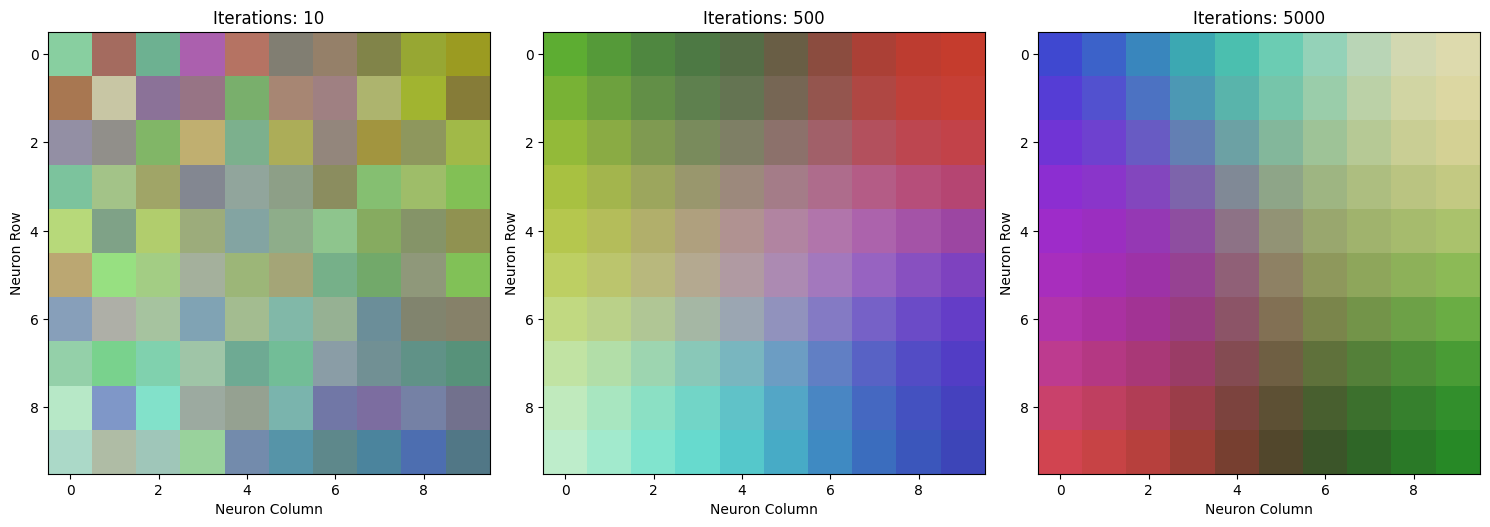


Part B


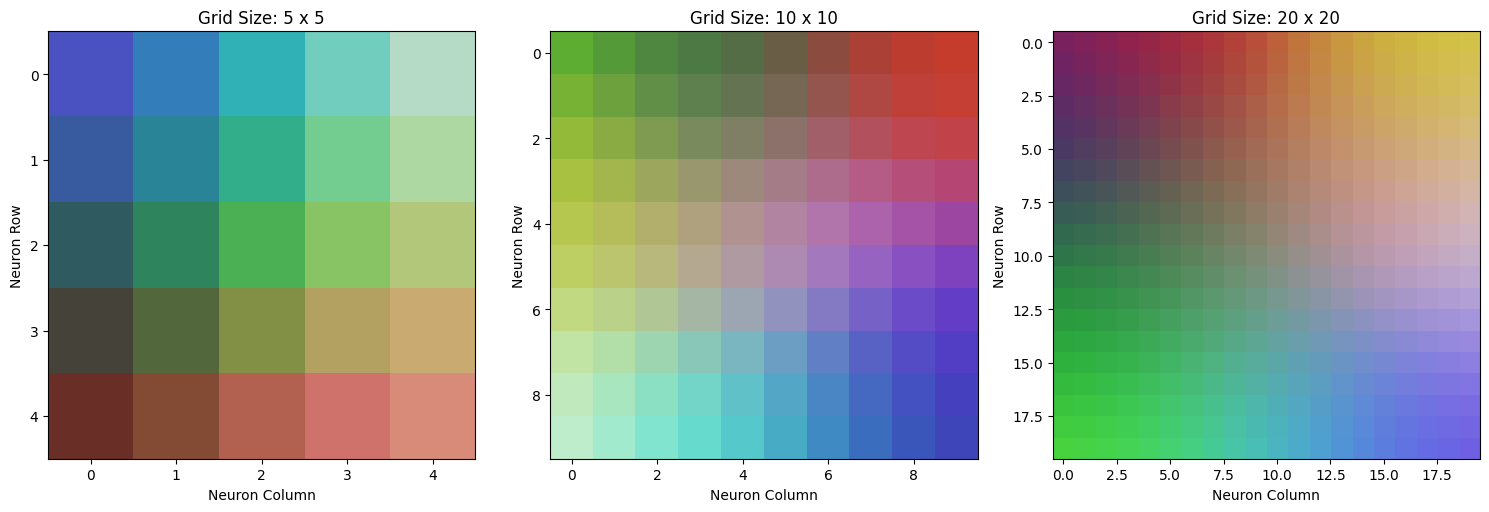


Part C


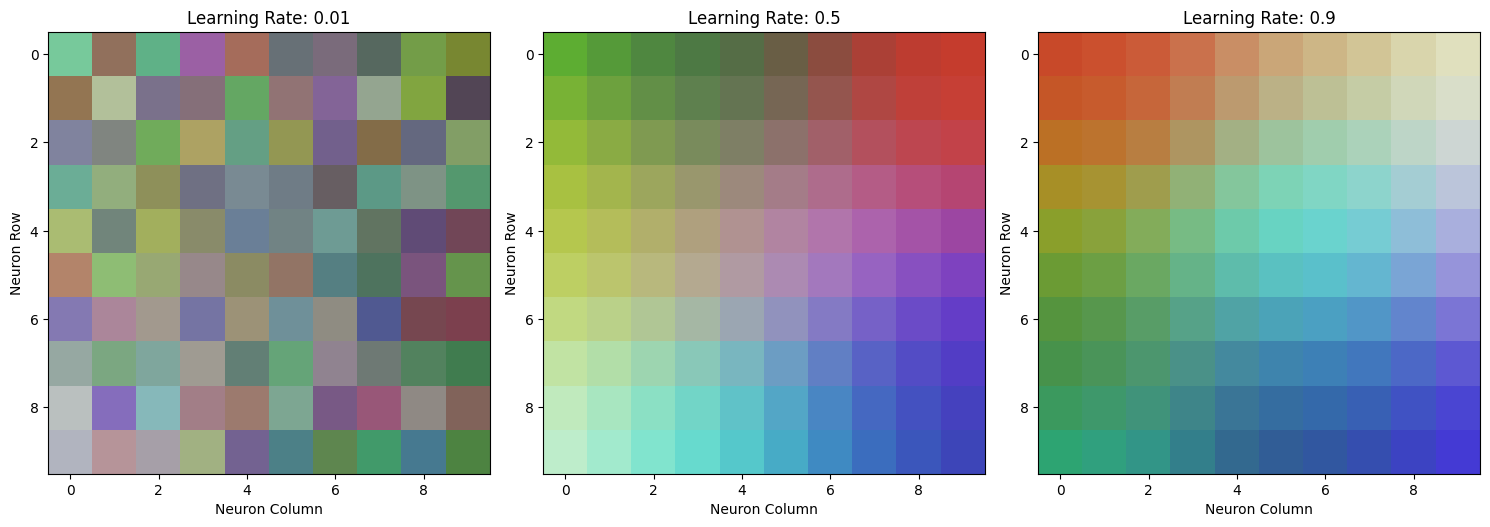


Part D
Setting Name         Value           Final Error         
-------------------------------------------------------
Iterations           10              0.266734
Iterations           500             0.208603
Iterations           5000            0.206206
Grid Size            5               0.234465
Grid Size            10              0.208603
Grid Size            20              0.206922
Learning Rate        0.01            0.257067
Learning Rate        0.5             0.208603
Learning Rate        0.9             0.219107


In [8]:
print("Part A")
experiment_results = []
iteration_values = [10,500,5000]
fig,axes = plt.subplots(1,3,figsize=(15,5))
for i,iterations in enumerate(iteration_values):
    np.random.seed(42)
    experiment_weights = np.random.rand(grid_size,grid_size,3)
    for j in range(iterations):
        learning_rate = 0.5 * np.exp(-j / iterations)
        radius = 5 * np.exp(-j / iterations)
        sample = data[np.random.randint(0,len(data))]
        distances = np.sqrt(np.sum((experiment_weights - sample) ** 2,axis=2))
        bmu = np.unravel_index(np.argmin(distances),distances.shape)
        h = neighborhood(grid_size,bmu,max(radius,0.01))
        experiment_weights += learning_rate * h[:,:,np.newaxis] * (sample - experiment_weights)
    error = quantization_error(data,experiment_weights)
    experiment_results.append(["Iterations",iterations,error])
    axes[i].imshow(experiment_weights)
    axes[i].set_title("Iterations: " + str(iterations))
    axes[i].set_xlabel("Neuron Column")
    axes[i].set_ylabel("Neuron Row")
plt.tight_layout()
plt.show()

print("\nPart B")
grid_values = [5,10,20]
fig,axes = plt.subplots(1,3,figsize=(15,5))
for i,size in enumerate(grid_values):
    np.random.seed(42)
    experiment_weights = np.random.rand(size,size,3)
    iterations = 500
    for j in range(iterations):
        learning_rate = 0.5 * np.exp(-j / iterations)
        radius = (size / 2) * np.exp(-j / iterations)
        sample = data[np.random.randint(0,len(data))]
        distances = np.sqrt(np.sum((experiment_weights - sample) ** 2,axis=2))
        bmu = np.unravel_index(np.argmin(distances),distances.shape)
        h = neighborhood(size,bmu,max(radius,0.01))
        experiment_weights += learning_rate * h[:,:,np.newaxis] * (sample - experiment_weights)
    error = quantization_error(data,experiment_weights)
    experiment_results.append(["Grid Size",size,error])
    axes[i].imshow(experiment_weights)
    axes[i].set_title("Grid Size: " + str(size) + " x " + str(size))
    axes[i].set_xlabel("Neuron Column")
    axes[i].set_ylabel("Neuron Row")
plt.tight_layout()
plt.show()

print("\nPart C")
learning_rate_values = [0.01,0.5,0.9]
fig,axes = plt.subplots(1,3,figsize=(15,5))
for i,lr_start in enumerate(learning_rate_values):
    np.random.seed(42)
    experiment_weights = np.random.rand(grid_size,grid_size,3)
    iterations = 500
    for j in range(iterations):
        learning_rate = lr_start * np.exp(-j / iterations)
        radius = 5 * np.exp(-j / iterations)
        sample = data[np.random.randint(0,len(data))]
        distances = np.sqrt(np.sum((experiment_weights - sample) ** 2,axis=2))
        bmu = np.unravel_index(np.argmin(distances),distances.shape)
        h = neighborhood(grid_size,bmu,max(radius,0.01))
        experiment_weights += learning_rate * h[:,:,np.newaxis] * (sample - experiment_weights)
    error = quantization_error(data,experiment_weights)
    experiment_results.append(["Learning Rate",lr_start,error])
    axes[i].imshow(experiment_weights)
    axes[i].set_title("Learning Rate: " + str(lr_start))
    axes[i].set_xlabel("Neuron Column")
    axes[i].set_ylabel("Neuron Row")
plt.tight_layout()
plt.show()

print("\nPart D")
print("{:<20} {:<15} {:<20}".format("Setting Name","Value","Final Error"))
print("-" * 55)
for result in experiment_results:
    print("{:<20} {:<15} {:.6f}".format(result[0],result[1],result[2]))

Task 9

Part A
Color data generated successfully
Data shape: (100, 3)
Minimum value: 0.0
Maximum value: 1.0


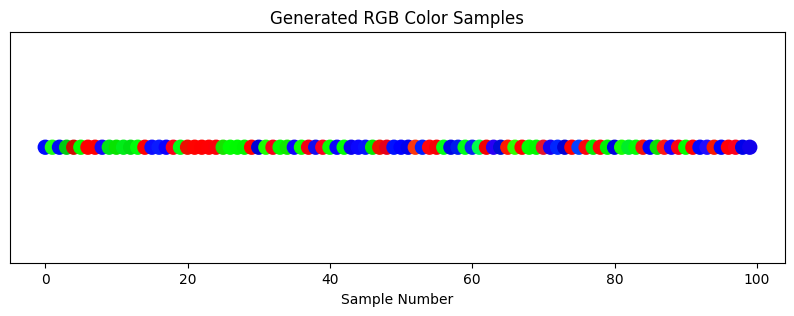


Part B
SOM training completed successfully
Trained weight shape: (10, 10, 3)


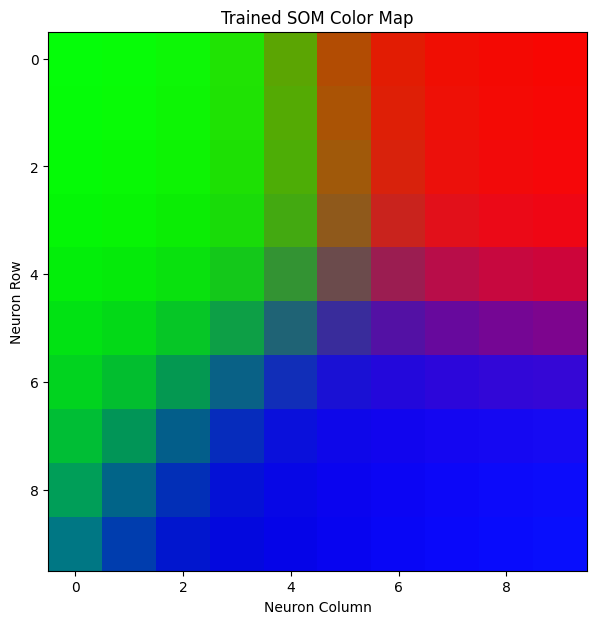


Part C
Samples grouped by BMU position
BMU: (9, 8) Number of samples: 1
BMU: (0, 2) Number of samples: 3
BMU: (9, 6) Number of samples: 1
BMU: (6, 0) Number of samples: 2
BMU: (0, 6) Number of samples: 1
BMU: (2, 0) Number of samples: 7
BMU: (0, 9) Number of samples: 12
BMU: (7, 9) Number of samples: 3
BMU: (5, 0) Number of samples: 4
BMU: (4, 1) Number of samples: 3
BMU: (0, 0) Number of samples: 5
BMU: (8, 9) Number of samples: 1
BMU: (9, 9) Number of samples: 8
BMU: (8, 7) Number of samples: 3
BMU: (3, 9) Number of samples: 6
BMU: (0, 7) Number of samples: 3
BMU: (2, 9) Number of samples: 3
BMU: (2, 3) Number of samples: 1
BMU: (3, 0) Number of samples: 2
BMU: (9, 3) Number of samples: 3
BMU: (3, 2) Number of samples: 1
BMU: (1, 1) Number of samples: 2
BMU: (7, 8) Number of samples: 2
BMU: (8, 5) Number of samples: 1
BMU: (9, 7) Number of samples: 5
BMU: (3, 8) Number of samples: 1
BMU: (9, 4) Number of samples: 3
BMU: (1, 6) Number of samples: 1
BMU: (1, 9) Number of samples: 2
BM

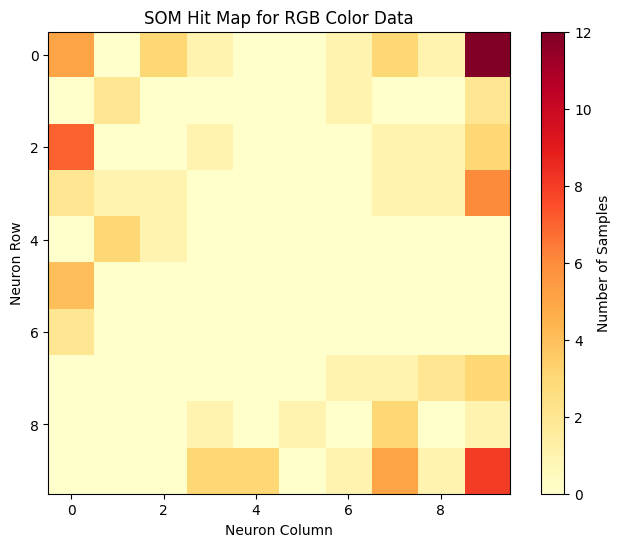

In [9]:
print("Part A")
np.random.seed(42)
base_colors = np.array([[1,0,0],[0,1,0],[0,0,1]])
data_colors = []
for i in range(100):
    base_color = base_colors[np.random.randint(0,3)]
    noise = np.random.normal(0,0.08,3)
    color = np.clip(base_color + noise,0,1)
    data_colors.append(color)
data_colors = np.array(data_colors)
print("Color data generated successfully")
print("Data shape:",data_colors.shape)
print("Minimum value:",np.min(data_colors))
print("Maximum value:",np.max(data_colors))
plt.figure(figsize=(10,3))
plt.scatter(range(len(data_colors)),np.zeros(len(data_colors)),c=data_colors,s=100)
plt.title("Generated RGB Color Samples")
plt.xlabel("Sample Number")
plt.yticks([])
plt.show()

print("\nPart B")
grid_size = 10
iterations = 2000
lr_start = 0.5
radius_start = 5
som_weights = np.random.rand(grid_size,grid_size,3)
initial_weights = som_weights.copy()
for iteration in range(iterations):
    learning_rate = lr_start * np.exp(-iteration / iterations)
    radius = radius_start * np.exp(-iteration / iterations)
    sample = data_colors[np.random.randint(0,len(data_colors))]
    distances = np.sqrt(np.sum((som_weights - sample) ** 2,axis=2))
    bmu = np.unravel_index(np.argmin(distances),distances.shape)
    h = neighborhood(grid_size,bmu,max(radius,0.01))
    som_weights += learning_rate * h[:,:,np.newaxis] * (sample - som_weights)
print("SOM training completed successfully")
print("Trained weight shape:",som_weights.shape)
plt.figure(figsize=(7,7))
plt.imshow(som_weights)
plt.title("Trained SOM Color Map")
plt.xlabel("Neuron Column")
plt.ylabel("Neuron Row")
plt.show()

print("\nPart C")
sample_groups = {}
hit_map = np.zeros((grid_size,grid_size),dtype=int)
for i in range(len(data_colors)):
    sample = data_colors[i]
    distances = np.sqrt(np.sum((som_weights - sample) ** 2,axis=2))
    bmu = np.unravel_index(np.argmin(distances),distances.shape)
    if bmu not in sample_groups:
        sample_groups[bmu] = []
    sample_groups[bmu].append(sample)
    hit_map[bmu[0],bmu[1]] += 1
print("Samples grouped by BMU position")
for position,samples in sample_groups.items():
    print("BMU:",position,"Number of samples:",len(samples))

print("\nPart D")
active_neurons = np.sum(hit_map > 0)
print("Total samples:",len(data_colors))
print("Neurons that received at least one sample:",active_neurons)
print("Total occupied groups:",len(sample_groups))
plt.figure(figsize=(8,6))
plt.imshow(hit_map,cmap="YlOrRd")
plt.title("SOM Hit Map for RGB Color Data")
plt.xlabel("Neuron Column")
plt.ylabel("Neuron Row")
plt.colorbar(label="Number of Samples")
plt.show()